# Indego Trips: Predicting Long-Duration Rides

**Project scaffold:** Can checkout-time information from 2024–2025 predict whether a trip in 2026 exceeds 30 minutes? This notebook contains a project workflow; the data overview is implemented and later analysis and modeling sections remain placeholders.

Run from this folder using the project environment: `python -m pip install -r requirements.txt`, then `python -m jupyter lab`. Select the kernel belonging to `.venv`. Quarterly CSVs remain unchanged in the data folder; Section 2 creates a combined cache if needed.

Each team member should document the **question, method, result, and interpretation** for their own sections. Results and conclusions are intentionally left blank.

## 0. Setup and Reproducibility

Import planned libraries, define the random seed and local paths. Add reusable utilities when needed.

In [1]:
from pathlib import Path
import re

import numpy as np
import pandas as pd
import polars as pl
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, confusion_matrix, f1_score,
                             precision_score, recall_score, precision_recall_curve)
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

RANDOM_STATE = 5450

## 1. Introduction and Research Questions

### 1.1 Motivation

When an Indego bike is in use, it is unavailable for another trip. Understanding which trips are likely to last longer can therefore provide a useful perspective on bike availability and fleet turnover.

This project examines whether information available at checkout can help identify long-duration trips. By learning from historical trip records and evaluating predictions on a later operating period, we connect rider, bike, and trip-start characteristics to a practical question for bike-share planning.

### 1.2 Prediction Objective

Our primary research question is:

> Can checkout-time information from 2024 and 2025 predict whether an Indego trip in 2026 will last more than 30 minutes?

We define a **long ride** as a trip lasting strictly more than 30 minutes; a trip lasting exactly 30 minutes is not classified as long. We will verify the source duration units before constructing the target.

The planned evaluation follows the order in which trips occur: 2024 and 2025 form the training period, 2026 Q1 and Q2 form the validation period, and 2026 Q3 is reserved for final testing. Predictors will use information available at checkout; trip duration will define the outcome.

### 1.3 Supporting Research Questions

1. How do long-ride rates vary across passholder types?
2. How do long-ride rates compare between morning rush (7:00 to 9:59) and evening rush (16:00 to 18:59)?
3. How do long-ride rates vary by bike type?
4. Which checkout-time characteristics provide useful information for predicting long rides?
5. How well do Logistic Regression, Random Forest, and Gradient Boosting predict trips in a later operating period?

Together, these questions connect patterns in rider and trip characteristics with the ability to predict long rides in a future period.

## 2. Data Source and Dataset Description

This section combines the 11 quarterly Indego trip files from 2024 Q1 through 2026 Q3, inspects the dataset, and prepares a working table for cleaning and modeling. The original quarterly files remain unchanged.

### 2.1 Load or Create the Combined Dataset

Load `data/full_data.csv` if it exists. Otherwise, convert 2026 Q3 timestamps to month/day/year format, preserving seconds, before combining the quarterly files. The original CSVs remain unchanged. When loading the combined data, treat the source `NULL` passholder label as missing.

In [2]:
DATA_DIR = Path("data")
FULL_DATA_PATH = DATA_DIR / "full_data.csv"

if not FULL_DATA_PATH.exists():
    quarterly_data = []
    for path in sorted(DATA_DIR.glob("indego-trips-*.csv")):
        year, quarter = re.search(r"(\d{4})-q([1-4])", path.name, re.IGNORECASE).groups()
        trips = pl.scan_csv(path, infer_schema=False)
        if (year, quarter) == ("2026", "3"):
            trips = trips.with_columns(
                pl.col("start_time", "end_time")
                .str.to_datetime("%Y-%m-%d %H:%M:%S", strict=True)
                .dt.strftime("%m/%d/%Y %H:%M:%S")
            )
        trips = trips.with_columns(
            pl.lit(int(year)).alias("source_year"),
            pl.lit(int(quarter)).alias("source_quarter"),
        )
        quarterly_data.append(trips)
    pl.concat(quarterly_data).sink_csv(FULL_DATA_PATH)
    print(f"Created {FULL_DATA_PATH} from {len(quarterly_data)} quarterly files.")
else:
    print(f"Loading existing {FULL_DATA_PATH}.")

full_data = pl.scan_csv(FULL_DATA_PATH, infer_schema=False, null_values={"passholder_type": "NULL"})

Loading existing data\full_data.csv.


### 2.2 Dataset Overview and Summary

Inspect the shape, columns, sample rows, missing values, and summary statistics. Numeric fields are converted for the summary; the saved CSV remains unchanged.

In [3]:
print("Shape (rows, columns):", (full_data.select(pl.len()).collect().item(), len(full_data.collect_schema())))
full_data.head().collect()

Shape (rows, columns): (3858309, 17)


trip_id,duration,start_time,end_time,start_station,start_lat,start_lon,end_station,end_lat,end_lon,bike_id,plan_duration,trip_route_category,passholder_type,bike_type,source_year,source_quarter
str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str
"""820756378""","""7""","""1/1/2024 0:04""","""1/1/2024 0:11""","""3125""","""39.943909""","""-75.167351""","""3010""","""39.947109""","""-75.166183""","""23172""","""30""","""One Way""","""Indego30""","""electric""","""2024""","""1"""
"""820756236""","""1""","""1/1/2024 0:04""","""1/1/2024 0:05""","""3068""","""39.93549""","""-75.167107""","""3068""","""39.93549""","""-75.167107""","""14667""","""30""","""Round Trip""","""Indego30""","""standard""","""2024""","""1"""
"""820756358""","""5""","""1/1/2024 0:05""","""1/1/2024 0:10""","""3068""","""39.93549""","""-75.167107""","""3086""","""39.940189""","""-75.166908""","""14667""","""30""","""One Way""","""Indego30""","""standard""","""2024""","""1"""
"""820756551""","""9""","""1/1/2024 0:08""","""1/1/2024 0:17""","""3049""","""39.945091""","""-75.142502""","""3063""","""39.946331""","""-75.1698""","""22420""","""30""","""One Way""","""Indego30""","""electric""","""2024""","""1"""
"""820886236""","""600""","""1/1/2024 0:11""","""1/1/2024 10:11""","""3010""","""39.947109""","""-75.166183""","""3236""","""39.96566""","""-75.17765""","""23095""","""30""","""One Way""","""Indego30""","""electric""","""2024""","""1"""


In [4]:
# Count missing values in each column.
full_data.select(pl.all().null_count()).collect().transpose(include_header=True, header_name="column", column_names=["missing_count"])

column,missing_count
str,u32
"""trip_id""",0
"""duration""",0
"""start_time""",0
"""end_time""",0
"""start_station""",0
…,…
"""trip_route_category""",0
"""passholder_type""",1602
"""bike_type""",0


In [5]:
# Describe numeric trip fields.
numeric_columns = ["duration", "start_lat", "start_lon", "end_lat", "end_lon", "plan_duration"]
full_data.select(pl.col(numeric_columns).cast(pl.Float64, strict=False)).collect().describe()

statistic,duration,start_lat,start_lon,end_lat,end_lon,plan_duration
str,f64,f64,f64,f64,f64,f64
"""count""",3.858309e6,3.858193e6,3.858193e6,3.79924e6,3.79924e6,3.858309e6
"""null_count""",0.0,116.0,116.0,59069.0,59069.0,0.0
"""mean""",16.647133,39.952282,-75.168915,39.952216,-75.16871,148.299131
"""std""",52.788842,0.015423,0.018646,0.015521,0.01873,163.364884
"""min""",1.0,39.007729,-75.249001,39.007729,-75.249001,1.0
"""25%""",6.0,39.943909,-75.17971,39.943909,-75.17971,30.0
"""50%""",10.0,39.95134,-75.16758,39.95134,-75.167381,30.0
"""75%""",16.0,39.96006,-75.156952,39.959999,-75.156723,365.0
"""max""",1440.0,40.030548,-75.101212,40.030548,-75.101212,365.0


### 2.3 Select Columns for Analysis

Remove destination and post-trip fields from the working table. Keep trip ID and source information for data checks, duration for the target, and checkout-time fields for analysis. Trip ID and source metadata will not be used as model predictors. The saved combined CSV keeps all original fields.

In [6]:
columns_to_drop = ["end_time", "end_station", "end_lat", "end_lon", "bike_id", "trip_route_category"]
analysis_data = full_data.drop(columns_to_drop)
analysis_data.head().collect()

trip_id,duration,start_time,start_station,start_lat,start_lon,plan_duration,passholder_type,bike_type,source_year,source_quarter
str,str,str,str,str,str,str,str,str,str,str
"""820756378""","""7""","""1/1/2024 0:04""","""3125""","""39.943909""","""-75.167351""","""30""","""Indego30""","""electric""","""2024""","""1"""
"""820756236""","""1""","""1/1/2024 0:04""","""3068""","""39.93549""","""-75.167107""","""30""","""Indego30""","""standard""","""2024""","""1"""
"""820756358""","""5""","""1/1/2024 0:05""","""3068""","""39.93549""","""-75.167107""","""30""","""Indego30""","""standard""","""2024""","""1"""
"""820756551""","""9""","""1/1/2024 0:08""","""3049""","""39.945091""","""-75.142502""","""30""","""Indego30""","""electric""","""2024""","""1"""
"""820886236""","""600""","""1/1/2024 0:11""","""3010""","""39.947109""","""-75.166183""","""30""","""Indego30""","""electric""","""2024""","""1"""


## 3. Data Validity and Cleaning

Convert fields to appropriate types, inspect data quality, and drop missing values from retained analysis columns. The source `NULL` passholder label is treated as missing.

### 3.1 Convert Types and Inspect Data Quality

Parse month/day/year timestamps, accepting both minute and second precision. Convert numeric columns and inspect null values, duplicate trip IDs, and nonpositive durations.

In [7]:
typed_data = analysis_data.with_columns(
    pl.coalesce(
        pl.col("start_time").str.to_datetime("%m/%d/%Y %H:%M:%S", strict=False),
        pl.col("start_time").str.to_datetime("%m/%d/%Y %H:%M", strict=False),
    ).alias("start_time"),
    pl.col("duration", "start_lat", "start_lon", "plan_duration").cast(pl.Float64, strict=False),
).collect()

display(typed_data.null_count().transpose(include_header=True, header_name="column", column_names=["missing_count"]))

column,missing_count
str,u32
"""trip_id""",0
"""duration""",0
"""start_time""",0
"""start_station""",0
"""start_lat""",116
…,…
"""plan_duration""",0
"""passholder_type""",1602
"""bike_type""",0


### 3.2 Apply Basic Validity Rules

Drop rows with missing values in retained columns, remove nonpositive durations, and keep one row per trip ID. Compare the dataset shape before and after cleaning.

In [8]:
clean_data = (
    typed_data.drop_nulls()
    .filter(pl.col("duration") > 0)
    .unique(subset="trip_id", keep="first", maintain_order=True)
)

print(f"Before & After cleaning: {typed_data.height:,} & {clean_data.height:,}")
print(f"Rows removed: {typed_data.height - clean_data.height:,}")

Before & After cleaning: 3,858,309 & 3,856,591
Rows removed: 1,718


**Findings.** Initial cleaning removes 1,718 rows: 1,602 with missing passholder type and 116 with missing starting coordinates. The dataset retains 3,856,591 trips.

## 4. Target Construction and Chronological Split

### 4.1 Define the Target

The outcome is `long_ride = 1` for a duration strictly greater than 30 minutes, and `0` otherwise. Duration defines the label and must not be used as a predictor.

In [9]:
data = clean_data.with_columns((pl.col("duration") > 30).cast(pl.Int8).alias("long_ride"))
data.head()

trip_id,duration,start_time,start_station,start_lat,start_lon,plan_duration,passholder_type,bike_type,source_year,source_quarter,long_ride
str,f64,datetime[μs],str,f64,f64,f64,str,str,str,str,i8
"""820756378""",7.0,2024-01-01 00:04:00,"""3125""",39.943909,-75.167351,30.0,"""Indego30""","""electric""","""2024""","""1""",0
"""820756236""",1.0,2024-01-01 00:04:00,"""3068""",39.93549,-75.167107,30.0,"""Indego30""","""standard""","""2024""","""1""",0
"""820756358""",5.0,2024-01-01 00:05:00,"""3068""",39.93549,-75.167107,30.0,"""Indego30""","""standard""","""2024""","""1""",0
"""820756551""",9.0,2024-01-01 00:08:00,"""3049""",39.945091,-75.142502,30.0,"""Indego30""","""electric""","""2024""","""1""",0
"""820886236""",600.0,2024-01-01 00:11:00,"""3010""",39.947109,-75.166183,30.0,"""Indego30""","""electric""","""2024""","""1""",1


### 4.2 Split by Start Time

Use 2024-2025 for training, 2026 Q1-Q2 for validation, and 2026 Q3 for the final test. The test outcomes are reserved for final evaluation.

In [10]:
train_data = data.filter((pl.col("start_time") >= pl.datetime(2024, 1, 1)) & (pl.col("start_time") < pl.datetime(2026, 1, 1)))
validation_data = data.filter((pl.col("start_time") >= pl.datetime(2026, 1, 1)) & (pl.col("start_time") < pl.datetime(2026, 7, 1)))
test_data = data.filter((pl.col("start_time") >= pl.datetime(2026, 7, 1)) & (pl.col("start_time") < pl.datetime(2026, 10, 1)))
print(f"Training: {train_data.height:,}; validation: {validation_data.height:,}; test: {test_data.height:,}")

Training: 2,626,258; validation: 689,135; test: 541,198


**Findings.** After initial cleaning, training, validation, and test contain 2,626,258, 689,135, and 541,198 trips. The EDA below uses training data before the additional exclusions in Section 5.6.

## 5. Exploratory Data Analysis

The following analysis uses the 2024-2025 training period. Each view connects a data pattern to a later modeling decision; observed differences describe associations.

### 5.0 Predictor Pair Plot and Correlation

Examine the numeric checkout-time predictors `start_lat`, `start_lon`, and `plan_duration` using training trips. `start_time` remains intact. Categorical variables and station IDs will be examined separately. Neither the target nor trip duration is included.

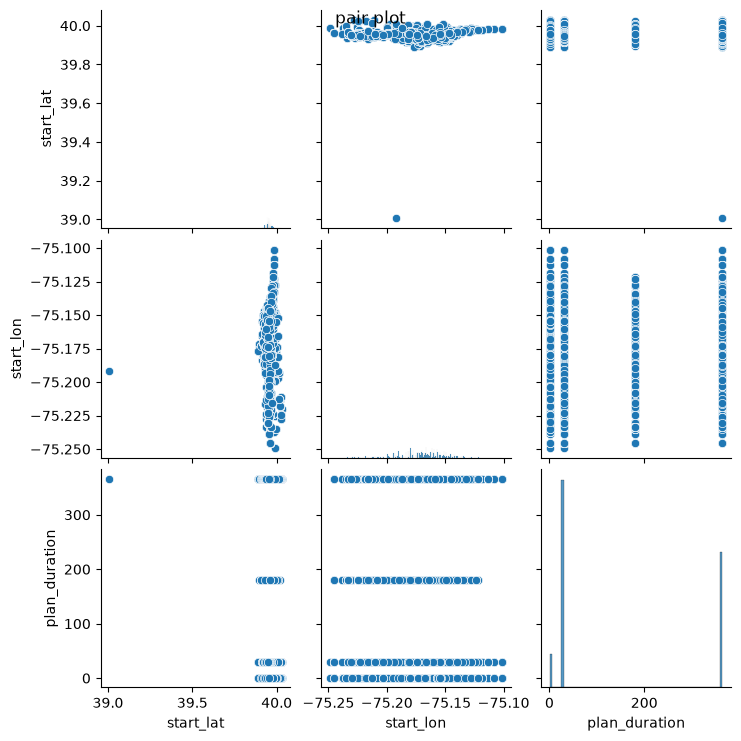

In [11]:
numeric_predictors = ["start_lat", "start_lon", "plan_duration"]
pair_data = train_data.select(numeric_predictors).to_pandas()

sns.pairplot(pair_data)
plt.suptitle("pair plot")
plt.show()

,start_lat,start_lon,plan_duration
start_lat,1.000000,-0.057398,-0.085599
start_lon,-0.057398,1.000000,-0.013955
plan_duration,-0.085599,-0.013955,1.000000


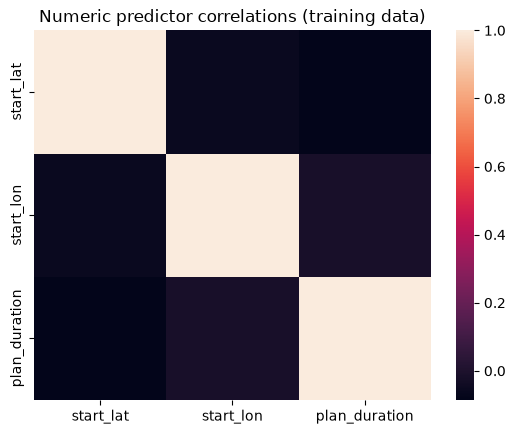

In [12]:
# Pearson correlation uses the full training set.
correlations = train_data.select(numeric_predictors).to_pandas().corr()
display(correlations)
plt.figure()
sns.heatmap(correlations)
plt.title("Numeric predictor correlations (training data)")
plt.show()

**Findings.** The pair plot reveals a potential low-latitude outlier near 39.0. The correlation matrix describes linear relationships among the numeric predictors. Latitude and longitude jointly represent geography, while `plan_duration` is discrete, so correlation alone does not determine which features to remove. We address the low-latitude observation after Section 5.5.

### 5.1 Trip Duration and Target Balance

Inspect typical trip duration, the long tail, and the share of rides above 30 minutes. The histogram focuses on the first 120 minutes for readability; summary statistics include all trips.

In [47]:
display(train_data.select("duration").describe())
display(train_data.group_by("long_ride").agg(pl.len().alias("trips")).sort("long_ride").with_columns((pl.col("trips") / train_data.height * 100).alias("percent")))

statistic,duration
str,f64
"""count""",2.626252e6
"""null_count""",0.0
"""mean""",16.43642
"""std""",51.594447
"""min""",1.0
"""25%""",6.0
"""50%""",10.0
"""75%""",16.0
"""max""",1440.0


long_ride,trips,percent
i8,u32,f64
0,2396188,91.239835
1,230064,8.760165


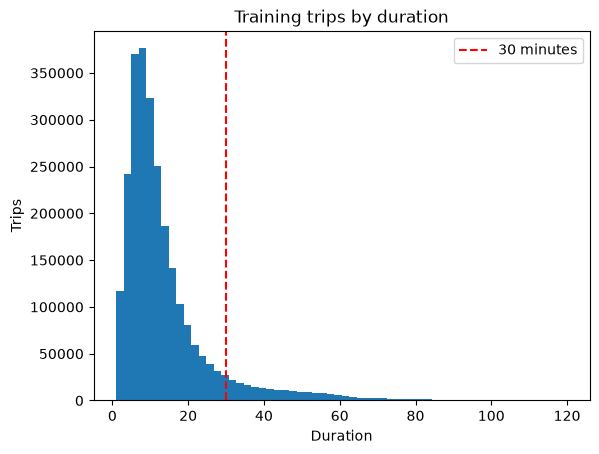

In [48]:
duration = train_data["duration"].to_numpy()
fig, ax = plt.subplots()
ax.hist(duration[duration <= 120], bins=60)
ax.axvline(30, color="red", linestyle="--", label="30 minutes")
ax.set(title="Training trips by duration", xlabel="Duration", ylabel="Trips")
ax.legend()
plt.show()

**Findings.** The histogram and summary describe training-trip duration and the long-ride class balance. Long positive trips are retained for now and will be investigated before any further duration filtering. Duration defines the target and cannot be a predictor.

### 5.2 Bike Type and Passholder Type

Compare long-ride rates and sample counts across checkout-time categories. Counts help distinguish a meaningful group from a small or sparse one.

,bike_type,trips,rate
0,electric,1630889,0.063099
1,standard,995369,0.127749


,passholder_type,trips,rate
0,Indego30,1450607,0.091467
1,Indego365,941820,0.030882
2,Walk-up,123727,0.212039
3,Day Pass,110099,0.382038
4,IndegoFlex,5,0.000000


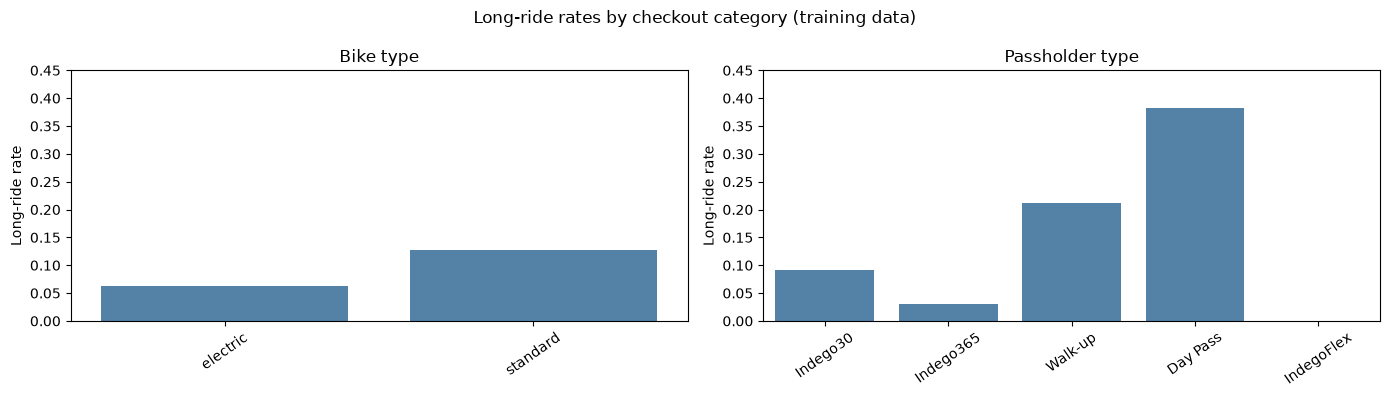

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, col, title in zip(axes, ["bike_type", "passholder_type"], ["Bike type", "Passholder type"]):
    rates = (train_data.group_by(col).agg(pl.len().alias("trips"), pl.col("long_ride").mean().alias("rate"))
             .sort("trips", descending=True).to_pandas())
    sns.barplot(data=rates, x=col, y="rate", color="blue", ax=ax)
    ax.set(title=title, xlabel="", ylabel="Long-ride rate")
    ax.tick_params(axis="x", rotation=30)
    display(rates[[col, "trips", "rate"]])
fig.suptitle("Long-ride rates(training data)")
plt.show()

**Findings.** The plots compare long-ride rates and sample sizes by bike type and passholder type. `IndegoFlex` appears rarely in the training data; it will be excluded after Section 5.5 as an inactive pass type. `Walk-up` remains its original source category.

### 5.3 Checkout Time

Plot the long-ride rate by checkout hour and day of week using training data. Rates use trips in each time group as the denominator.

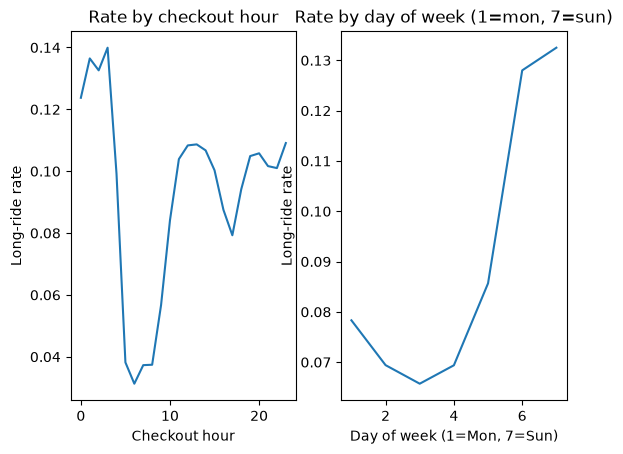

In [48]:
time_data = train_data.with_columns(
    pl.col("start_time").dt.hour().alias("hour"),
    pl.col("start_time").dt.weekday().alias("weekday"),
)
fig, axes = plt.subplots(1, 2)
for ax, col, xlabel in zip(axes, ["hour", "weekday"], ["Checkout hour", "Day of week (1=Mon, 7=Sun)"]):
    rates = time_data.group_by(col).agg(pl.col("long_ride").mean().alias("rate")).sort(col).to_pandas()
    sns.lineplot(data=rates, x=col, y="rate", ax=ax)
    ax.set(xlabel=xlabel, ylabel="Long-ride rate", title=f"Rate by {xlabel.lower()}")
plt.show()

**Findings.** The plots show how long-ride rates vary by checkout hour and weekday. These patterns can guide the later construction of time features and the planned rush-period comparison.

### 5.4 Starting Stations and Geography

Aggregate trips by starting station to avoid plotting millions of overlapping points. Display stations with at least 100 training trips and valid coordinates; point color represents the station's long-ride rate.

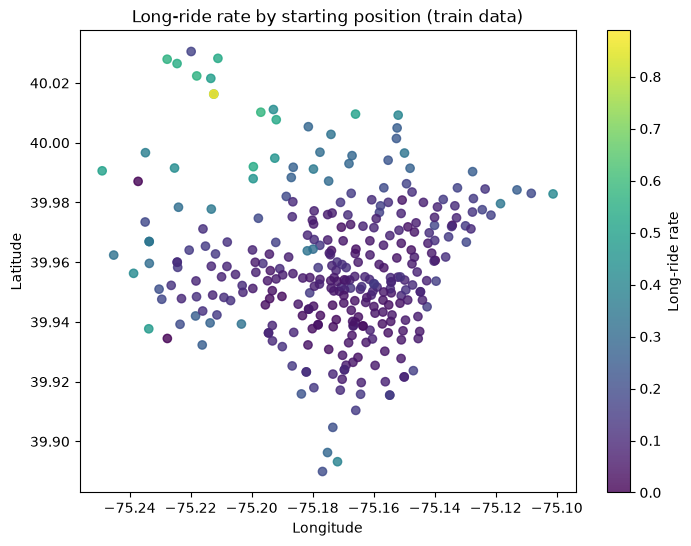

Stations plotted: 315


In [58]:
stations = (train_data.group_by("start_station").agg(
    pl.len().alias("trips"), pl.col("long_ride").mean().alias("rate"),
    pl.col("start_lat").median().alias("latitude"), pl.col("start_lon").median().alias("longitude"),
).to_pandas())
fig, ax = plt.subplots(figsize = (8, 6))
points = ax.scatter(stations["longitude"], stations["latitude"], c=stations["rate"], cmap="viridis", alpha=0.8)
fig.colorbar(points, ax=ax, label="Long-ride rate")
ax.set(title="Long-ride rate by starting position (train data)", xlabel="Longitude", ylabel="Latitude")
plt.show()
print(f"Stations plotted: {len(stations)}")

**Findings.** Station-level rates provide a geographic view of long rides without overplotting individual trips. Sample-size filtering makes the displayed rates easier to interpret. Starting station and coordinates may encode overlapping location information, so their representations should be compared during feature engineering.

### 5.5 Remaining Missingness and Feature Overlap

Confirm that the retained analysis columns have no nulls after cleaning. Compare passholder type and plan duration to inform later feature selection.

In [59]:
train_data.group_by("passholder_type", "plan_duration").agg(pl.len().alias("trips")).sort("trips", descending=True)

passholder_type,plan_duration,trips
str,f64,u32
"""Indego30""",30.0,1448327
"""Indego365""",365.0,940028
"""Walk-up""",1.0,123727
"""Day Pass""",1.0,110099
"""Indego30""",365.0,2280
"""Indego180""",180.0,1791


**Findings.** The cleaning rule removes rows with nulls in retained analysis columns. Passholder type and plan duration should be considered together because several passholder categories are strongly associated with particular plan lengths.

### 5.6 Apply EDA-Informed Cleaning

Exclude trips with `IndegoFlex` or `start_lat < 39.1`. Relabel records with `passholder_type = Indego365` and `plan_duration = 180` as `Indego180` for this analysis. Apply the same rules to all periods; the EDA above describes the data before these changes.

In [ ]:
before_eda_cleaning = data.height

# Apply the same EDA-informed rules to the full dataset and each split.
def apply_eda_exclusions(frame):
    return (
        frame.filter((pl.col("passholder_type") != "IndegoFlex") & (pl.col("start_lat") >= 39.1))
        .with_columns(
            pl.when((pl.col("passholder_type") == "Indego365") & (pl.col("plan_duration") == 180))
            .then(pl.lit("Indego180"))
            .otherwise(pl.col("passholder_type"))
            .alias("passholder_type")
        )
    )

data = apply_eda_exclusions(data)
train_data = apply_eda_exclusions(train_data)
validation_data = apply_eda_exclusions(validation_data)
test_data = apply_eda_exclusions(test_data)

print(f"Before & after EDA exclusions: {before_eda_cleaning:,} & {data.height:,}")
print(f"Rows removed: {before_eda_cleaning - data.height:,}")
print(f"Training: {train_data.height:,}; validation: {validation_data.height:,}; test: {test_data.height:,}")

**Findings.** The exclusion rules remove 6 trips: 5 with `IndegoFlex` and 1 with `start_lat < 39.1`. The 180-day `Indego365` records are relabeled `Indego180`; relabeling does not remove rows. Subsequent analysis uses the updated splits.

## 6. Hypothesis Testing

### 6.1 Passholder type

On training data, test whether long-ride rates differ across passholder groups using a permutation test. Report group rates, effect size, null distribution, and p-value.

In [19]:
# TODO: Implement this section.


### 6.2 Morning versus evening rush

On training data, compare 07:00–09:59 and 16:00–18:59 using a two-sided permutation test of the difference in long-ride rates. Report the effect and null distribution.

In [20]:
# TODO: Implement this section.


### 6.3 Interpretation

Explain assumptions and practical meaning, and consider dependence or temporal structure when defining a valid permutation scheme.

In [21]:
# TODO: Implement this section.


## 7. Feature Engineering

### 7.1 Checkout-time features

Derive hour, weekday, month, season, weekend, and rush indicators from start time.

In [22]:
# TODO: Implement this section.


### 7.2 Geography and interactions

Consider start station or coordinates and a small number of interpretable interactions; confirm availability at checkout.

In [23]:
# TODO: Implement this section.


### 7.3 Redundancy

Examine overlapping plan, time, station, and coordinate features, especially for coefficient interpretation.

In [24]:
# TODO: Implement this section.


## 8. Preprocessing Pipeline

### 8.1 Numeric features

Plan median imputation and scaling where appropriate, especially for Logistic Regression.

In [25]:
# TODO: Implement this section.


### 8.2 Categorical features

Plan imputation and one-hot encoding with unknown categories handled safely.

In [26]:
# TODO: Implement this section.


### 8.3 Leakage prevention

Combine preprocessing and estimator in a scikit-learn pipeline and fit only on training folds.

In [27]:
# TODO: Implement this section.


## 9. Modeling Framework

### 9.1 Logistic Regression

Build an interpretable regularized baseline; investigate coefficients, odds ratios, and selected interactions.

In [28]:
# TODO: Implement this section.


### 9.2 Random Forest

Train a tree ensemble and consider tree count, depth, leaf size, feature subsampling, and class weights.

In [29]:
# TODO: Implement this section.


### 9.3 Gradient Boosting

Train a sequential boosting model; consider learning rate, number of trees, depth, leaf size, and subsampling.

In [30]:
# TODO: Implement this section.


## 10. Hyperparameter Tuning and Model Selection

### 10.1 Time-aware validation

If cross-validating within 2024–2025, use expanding time windows; do not use random stratified folds.

In [31]:
# TODO: Implement this section.


### 10.2 Compare on validation

Compare precision, recall, F1, PR-AUC, and confusion matrices. Use validation F1 as the proposed selection metric, with recall and stability considered.

In [32]:
# TODO: Implement this section.


### 10.3 Select decision threshold

Choose a threshold using validation only, then freeze the model and threshold before final testing.

In [33]:
# TODO: Implement this section.


## 11. Final Test-Set Evaluation

### 11.1 Evaluate the frozen model

Evaluate on 2026 Q3 only after selection. Report precision, recall, F1, PR-AUC, confusion matrix, and precision-recall curve.

In [34]:
# TODO: Implement this section.


### 11.2 Error analysis

Summarize false positives and false negatives without using test outcomes to retune the model.

In [35]:
# TODO: Implement this section.


## 12. Bootstrap Confidence Intervals

### 12.1 Resampling

Bootstrap final test predictions for intervals for precision, recall, F1, and PR-AUC; document the resampling unit and any dependence assumptions.

In [36]:
# TODO: Implement this section.


### 12.2 Interpretation

Report 95% confidence intervals and interpret uncertainty rather than using them to select the model.

In [37]:
# TODO: Implement this section.


## 13. Prediction Interpretation

### 13.1 Logistic Regression

Interpret coefficients and odds ratios with attention to interactions and correlated features.

In [38]:
# TODO: Implement this section.


### 13.2 Tree ensembles

Compare feature importance with permutation importance; describe how correlated predictors can share importance.

In [39]:
# TODO: Implement this section.


### 13.3 Connect the findings

Relate descriptive patterns, hypothesis tests, predictive importance, and temporal generalization without claiming causation.

In [40]:
# TODO: Implement this section.


## 14. Challenges

### 14.1 Data validity

Document data-quality rules and their effect on the dataset.

In [41]:
# TODO: Implement this section.


### 14.2 Temporal distribution shift

Compare training and later periods and discuss differences that affect generalization.

In [42]:
# TODO: Implement this section.


### 14.3 Class imbalance

Assess prevalence and use precision, recall, F1, and PR-AUC rather than accuracy alone.

In [43]:
# TODO: Implement this section.


### 14.4 Feature redundancy and high cardinality

Discuss overlapping predictors and station categories in modeling and interpretation.

In [44]:
# TODO: Implement this section.


## 15. Conclusion

### 15.1 Findings and implications

After the analysis, answer the research questions, compare models, identify useful checkout-time information, and discuss fleet-turnover implications.

In [45]:
# TODO: Implement this section.


### 15.2 Limitations and next steps

Document limitations, uncertainty, and follow-up work based on observed results.

In [46]:
# TODO: Implement this section.


## Team Responsibilities

| Member | Main responsibilities |
| --- | --- |
| 1 | Data import, quality, target, feature engineering, and preprocessing |
| 2 | Introduction, EDA, visualizations, hypothesis tests, and narrative review |
| 3 | Logistic Regression, Gradient Boosting, tuning, validation, and interpretation |
| 4 | Random Forest, model comparison, threshold, final test, bootstrap, and permutation importance |

Each member documents the purpose, method, results, and interpretation of their own work.